# ECE285 HW1: Variational Autoencoder for Chest X-ray Generation

This notebook trains VAEs on the Kaggle *Chest X-Ray Images (Pneumonia)* dataset and evaluates the
generated images with Inception Score (IS) and FID, using `pytorch-ignite` as in
https://pytorch-ignite.ai/blog/gan-evaluation-with-fid-and-is/.

It has two models:

* **Part A, baseline VAE.** A standard convolutional VAE with a single 128-d latent and a Bernoulli
  (BCE) likelihood. It learns the overall anatomy, but its samples are **blurry**: the rib edges are
  washed out. Its validation loss also stops improving while the training loss keeps falling
  (**over-fitting**).
* **Part B, improved VAE.** It addresses both problems:
  1. **Hierarchical latent space.** A global latent $z_1$ (128-d) plus a *spatial* latent
     $z_2\in\mathbb R^{4\times16\times16}$ with a learned conditional prior $p(z_2\mid z_1)$. The fine
     local structure (rib positions, lung texture) no longer has to pass through one 128-d vector.
     A single global code can't store each patient's rib pattern, so the decoder used to average it
     away.
  2. **Perceptual (VGG feature) reconstruction loss**, added to the pixel likelihood. Pixel losses
     reward blurry averages; a feature loss rewards correct edges and texture. This is what makes
     $z_2$ actually get used.
  3. **Against over-fitting:** a proper train/validation split, on-the-fly data augmentation (small
     rotations, shifts, zooms, brightness/contrast; no flips, since anatomy is not left/right
     symmetric), AdamW weight decay, gradient clipping, and **early stopping** on the validation loss
     (the best checkpoint is kept).

Steps: 1 setup → 2 data → 3 shared utilities → 4 Part A → 5 Part B → 6 loss curves and over-fitting →
7 image comparison → 8 IS/FID → 9 summary. All figures and numbers are saved to `outputs/`.

## 1. Setup

In [2]:
import os, json, time, math, random
from glob import glob

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
import torchvision.utils as vutils

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch", torch.__version__, "| device:", device,
      "|", torch.cuda.get_device_name(0) if device.type == "cuda" else "")

# Speed-ups on the RTX 5070 Ti: let cuDNN pick the fastest conv algorithms, and allow TF32 matmuls.
torch.backends.cudnn.benchmark = True
torch.backends.cuda.matmul.allow_tf32 = True
torch.backends.cudnn.allow_tf32 = True

OUT_DIR = "outputs"
os.makedirs(OUT_DIR, exist_ok=True)


def set_seed(seed: int) -> None:
    # Seed Python, NumPy and PyTorch (CPU + CUDA) RNGs so runs are reproducible.
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

PyTorch 2.8.0.dev20250518+cu128 | device: cuda | NVIDIA GeForce RTX 5070 Ti


In [3]:
# ---- Hyperparameters (reported in the write-up) ----
DATA = dict(data_root="chest_xray", img_size=128, val_frac=0.10, seed=42)

CFG_BASE = dict(                 # Part A: baseline VAE
    name="baseline", latent_dim=128, enc_channels=[32, 64, 128, 256, 512],
    batch_size=64, epochs=150, lr=1e-3, lr_min=1e-5, weight_decay=0.0,
    beta_kl=1.0, kl_warmup=10, lam_perc=0.0, augment=False, grad_clip=None,
    early_stop_patience=None,    # no early stopping: keep the last epoch
)

CFG_IMPR = dict(                 # Part B: improved hierarchical VAE
    name="improved", latent_dim=128, z2_channels=4,          # z1: 128-d global, z2: 4 x 16 x 16 spatial
    batch_size=64, epochs=150, lr=1e-3, lr_min=1e-5, weight_decay=1e-4,
    beta_kl=1.0, kl_warmup=10, lam_perc=0.02,             # weight of the VGG perceptual loss
    augment=True, grad_clip=200.0, early_stop_patience=30,   # stop if val loss hasn't improved for 30 epochs
)

N_EVAL = 5000          # max number of generated / real images used for IS & FID

# False: if outputs/<name>.pt and outputs/history_<name>.json already exist, load them instead of training
# (after a kernel restart, "Run All" goes straight to the evaluation). True: always train from scratch.
# Set it to True whenever you change a model hyperparameter, otherwise the old weights are reused.
RETRAIN = False

with open(os.path.join(OUT_DIR, "hparams.json"), "w") as f:
    json.dump(dict(data=DATA, baseline=CFG_BASE, improved=CFG_IMPR, n_eval=N_EVAL), f, indent=2)
print(json.dumps(dict(baseline=CFG_BASE, improved=CFG_IMPR), indent=1))

{
 "baseline": {
  "name": "baseline",
  "latent_dim": 128,
  "enc_channels": [
   32,
   64,
   128,
   256,
   512
  ],
  "batch_size": 64,
  "epochs": 150,
  "lr": 0.001,
  "lr_min": 1e-05,
  "weight_decay": 0.0,
  "beta_kl": 1.0,
  "kl_warmup": 10,
  "lam_perc": 0.0,
  "augment": false,
  "grad_clip": null,
  "early_stop_patience": null
 },
 "improved": {
  "name": "improved",
  "latent_dim": 128,
  "z2_channels": 4,
  "batch_size": 64,
  "epochs": 150,
  "lr": 0.001,
  "lr_min": 1e-05,
  "weight_decay": 0.0001,
  "beta_kl": 1.0,
  "kl_warmup": 10,
  "lam_perc": 0.02,
  "augment": true,
  "grad_clip": 200.0,
  "early_stop_patience": 30
 }
}


## 2. Data

The dataset has `train/`, `val/` and `test/` folders, each with `NORMAL/` and `PNEUMONIA/` sub-folders.
The VAE is unsupervised, so labels are ignored.

* **train**: 90% of `train/` + `val/` (the official `val/` has only 16 images), used to fit the models.
* **val**: the other 10%, used to monitor over-fitting and for early stopping.
* **test** (624 images): never used for training or model selection; reported at the end.

The X-rays are large (≈1000–2000 px) JPEGs, so decoding them is slow. We decode once, convert to
grayscale, resize to 128×128, and cache the result as a `uint8` tensor. The whole dataset (≈90 MB)
then stays **on the GPU**, so batching is just tensor indexing with no DataLoader bottleneck.

In [4]:
def list_images(root: str, splits) -> list:
    # Return sorted paths of every .jpeg/.jpg/.png image under root/<split>/<class>/ for the given splits.
    paths = []
    for s in splits:
        for ext in ("jpeg", "jpg", "png"):
            paths += glob(os.path.join(root, s, "*", f"*.{ext}"))
    return sorted(paths)


def load_images(paths: list, size: int) -> torch.Tensor:
    # Read images, convert to grayscale ('L'), resize to size x size (bicubic), and stack into
    # a uint8 tensor of shape (N, 1, size, size).
    arr = np.empty((len(paths), 1, size, size), dtype=np.uint8)
    for i, p in enumerate(paths):
        img = Image.open(p).convert("L").resize((size, size), Image.BICUBIC)
        arr[i, 0] = np.asarray(img)
    return torch.from_numpy(arr)


def cached_split(name: str, splits, size: int) -> torch.Tensor:
    # Load a split from the .pt cache if present; otherwise decode the JPEGs and write the cache.
    cache = os.path.join(OUT_DIR, f"cache_{name}_{size}.pt")
    if os.path.exists(cache):
        return torch.load(cache)
    t0 = time.time()
    x = load_images(list_images(DATA["data_root"], splits), size)
    torch.save(x, cache)
    print(f"decoded {len(x)} images for '{name}' in {time.time() - t0:.1f}s")
    return x


trainval_u8 = cached_split("trainval", ["train", "val"], DATA["img_size"])
test_u8 = cached_split("test", ["test"], DATA["img_size"])

# Random 90/10 train/val split (fixed seed), then move everything to the GPU as float in [0, 1].
g = torch.Generator().manual_seed(DATA["seed"])
perm = torch.randperm(len(trainval_u8), generator=g)
n_val = int(len(perm) * DATA["val_frac"])
train_x = trainval_u8[perm[n_val:]].to(device).float().div_(255)
val_x = trainval_u8[perm[:n_val]].to(device).float().div_(255)
test_x = test_u8.to(device).float().div_(255)
print(f"train {tuple(train_x.shape)} | val {tuple(val_x.shape)} | test {tuple(test_x.shape)} "
      f"| pixel mean {train_x.mean():.3f}, std {train_x.std():.3f}")

train (4709, 1, 128, 128) | val (523, 1, 128, 128) | test (624, 1, 128, 128) | pixel mean 0.483, std 0.236


## 3. Shared utilities: batching, plotting, augmentation

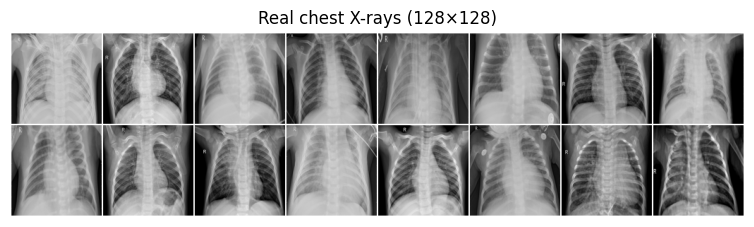

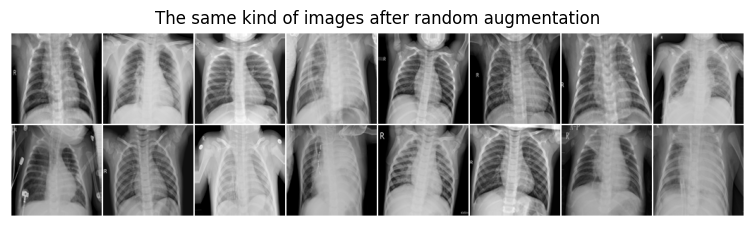

In [5]:
def iterate_minibatches(x: torch.Tensor, batch_size: int, shuffle: bool = True):
    # Yield mini-batches from a tensor already on the GPU (a random permutation each epoch if shuffle).
    idx = torch.randperm(len(x), device=x.device) if shuffle else torch.arange(len(x), device=x.device)
    for i in range(0, len(x), batch_size):
        yield x[idx[i:i + batch_size]]


def show_grid(imgs: torch.Tensor, title: str, nrow: int = 8, fname: str = None, scale: float = 1.2) -> None:
    # Draw a batch of (N,1,H,W) images in [0,1] as one grid; optionally save it to outputs/<fname>.
    grid = vutils.make_grid(imgs.detach().float().cpu().clamp(0, 1), nrow=nrow, padding=2, pad_value=1)
    plt.figure(figsize=(nrow * scale, math.ceil(len(imgs) / nrow) * scale))
    plt.imshow(grid.permute(1, 2, 0).numpy(), cmap="gray", vmin=0, vmax=1)
    plt.axis("off"); plt.title(title)
    if fname:
        plt.savefig(os.path.join(OUT_DIR, fname), bbox_inches="tight", dpi=150)
    plt.show()


def augment(x: torch.Tensor) -> torch.Tensor:
    # Random augmentation of a GPU batch (B,1,H,W) in [0,1]: rotation ±5°, zoom ±5%, shift ±4%
    # (bicubic resampling, border padding) and brightness ±0.05 / contrast ±10%. No horizontal flips,
    # because the heart is on the left side and flipped X-rays would be anatomically wrong.
    B = x.size(0)
    r = lambda: torch.rand(B, device=x.device) * 2 - 1           # uniform in [-1, 1]
    ang, scale = r() * math.radians(5), 1 + r() * 0.05
    cos, sin = torch.cos(ang) / scale, torch.sin(ang) / scale
    theta = torch.stack([torch.stack([cos, -sin, r() * 0.04], 1),
                         torch.stack([sin, cos, r() * 0.04], 1)], 1)
    grid = F.affine_grid(theta, x.shape, align_corners=False)
    x = F.grid_sample(x, grid, mode="bicubic", padding_mode="border", align_corners=False)
    m = x.mean((1, 2, 3), keepdim=True)
    x = (x - m) * (1 + 0.10 * r().view(B, 1, 1, 1)) + m + 0.05 * r().view(B, 1, 1, 1)
    return x.clamp(0, 1)


show_grid(train_x[torch.randperm(len(train_x))[:16]], "Real chest X-rays (128×128)", fname="real_samples.png")
show_grid(augment(train_x[:16]), "The same kind of images after random augmentation", fname="augmentation.png")

## 4. Part A: baseline VAE

**Encoder** $q_\phi(z\mid x)$: 5 stride-2 conv blocks (Conv → BatchNorm → LeakyReLU) shrink
$1\times128\times128$ to $512\times4\times4$. Two linear heads output the mean $\mu$ and log-variance
$\log\sigma^2$ of a diagonal Gaussian. **Reparameterization**: $z=\mu+\sigma\odot\epsilon$,
$\epsilon\sim\mathcal N(0,I)$. **Decoder** $p_\theta(x\mid z)$ mirrors the encoder with transposed
convolutions and outputs per-pixel logits; $\text{sigmoid}(\cdot)$ is the image.

Both models below share one interface, so the same training and evaluation code works for each:
* `forward(x) -> (logits, kl_1, kl_2)`, with the KL terms averaged over the batch ($kl_2=0$ for the baseline),
* `reconstruct(x)` decodes the posterior mean, `sample(n)` decodes prior samples, and
  `encode_top(x)` returns the global latent $(\mu, \log\sigma^2)$.

**Loss: negative ELBO**
$$\mathcal L = \underbrace{\text{BCE}(x,\hat x)}_{-\log p(x|z)\text{, summed over pixels}}
+\beta\,D_{KL}\big(q(z|x)\,\|\,\mathcal N(0,I)\big),\qquad
D_{KL}=-\tfrac12\sum_j(1+\log\sigma_j^2-\mu_j^2-\sigma_j^2)$$
with KL warm-up: $\beta$ goes linearly 0 → 1 over the first 10 epochs, which helps avoid posterior collapse.

In [6]:
def kl_std_normal(mu, logvar):
    # KL( N(mu, sigma^2) || N(0, I) ), summed over latent dimensions and averaged over the batch.
    return -0.5 * torch.sum(1 + logvar - mu.pow(2) - logvar.exp()) / mu.size(0)


def reparameterize(mu, logvar):
    # Sample z = mu + sigma * eps with eps ~ N(0, I) so gradients flow through mu and sigma.
    return mu + torch.exp(0.5 * logvar) * torch.randn_like(mu)


class BaselineVAE(nn.Module):
    # Part A model: conv encoder -> single 128-d Gaussian latent -> transposed-conv decoder.
    def __init__(self, img_size=128, latent_dim=128, channels=(32, 64, 128, 256, 512)):
        super().__init__()
        self.latent_dim = latent_dim
        layers, c_in = [], 1
        for c in channels:                                        # 128 -> 64 -> 32 -> 16 -> 8 -> 4
            layers += [nn.Conv2d(c_in, c, 4, 2, 1, bias=False), nn.BatchNorm2d(c), nn.LeakyReLU(0.2, True)]
            c_in = c
        self.enc = nn.Sequential(*layers, nn.Flatten())
        self.hw = img_size // 2 ** len(channels)
        feat = channels[-1] * self.hw ** 2
        self.fc_mu, self.fc_logvar = nn.Linear(feat, latent_dim), nn.Linear(feat, latent_dim)

        ch = list(channels)[::-1]                                 # [512, 256, 128, 64, 32]
        self.fc_dec = nn.Sequential(nn.Linear(latent_dim, feat), nn.ReLU(True))
        layers = []
        for a, b in zip(ch, ch[1:] + [ch[-1]]):                   # 4 -> 8 -> 16 -> 32 -> 64 -> 128
            layers += [nn.ConvTranspose2d(a, b, 4, 2, 1, bias=False), nn.BatchNorm2d(b), nn.LeakyReLU(0.2, True)]
        self.dec = nn.Sequential(*layers, nn.Conv2d(ch[-1], 1, 3, 1, 1))

    def encode_top(self, x):
        # Return (mu, logvar) of q(z|x).
        h = self.enc(x)
        return self.fc_mu(h), self.fc_logvar(h)

    def decode(self, z):
        # Map latent codes z (B, latent_dim) to pixel logits (B, 1, H, W).
        return self.dec(self.fc_dec(z).view(z.size(0), -1, self.hw, self.hw))

    def forward(self, x):
        mu, logvar = self.encode_top(x)
        return self.decode(reparameterize(mu, logvar)), kl_std_normal(mu, logvar), torch.zeros((), device=x.device)

    @torch.no_grad()
    def reconstruct(self, x):
        # Deterministic reconstruction from the posterior mean, in [0, 1].
        return torch.sigmoid(self.decode(self.encode_top(x)[0]))

    @torch.no_grad()
    def sample(self, n, z=None):
        # Generate n images by decoding z ~ N(0, I) (or the given z), in [0, 1].
        z = torch.randn(n, self.latent_dim, device=device) if z is None else z
        return torch.sigmoid(self.decode(z))

### Generic training loop (used for both models)

Each step minimizes
$\;\text{BCE} + \lambda_{perc}\cdot\text{Perceptual} + \beta\,(KL_1 + KL_2)$
(for the baseline, $\lambda_{perc}=0$ and $KL_2=0$, which is the plain negative ELBO).

After every epoch we evaluate **without augmentation** and with $\beta=1$ on (a) a fixed subset of the
training images and (b) the validation set. We log the negative ELBO and the full objective. The gap
between validation and train **−ELBO** measures over-fitting. With early stopping enabled, the
checkpoint with the lowest validation objective is kept, and training stops after `patience` epochs
without improvement.

**Saving and resuming.** The checkpoint and the loss history are written to `outputs/` after every
epoch. `load_or_train` loads them if they exist, unless `RETRAIN = True`, so after a kernel restart or
page refresh **Run All** skips training and goes straight to the evaluation (Parts 6–9). Pressing
the stop button during training also stops cleanly: it keeps the best checkpoint and the history so far,
and the later cells still work.

In [7]:
class PerceptualLoss(nn.Module):
    # VGG16 feature-matching loss: squared distance between ImageNet-VGG16 activations (relu1_2, relu2_2,
    # relu3_3) of the reconstruction and the target. Grayscale inputs are repeated to 3 channels and
    # ImageNet-normalized. Each layer's mean squared error is multiplied by the number of pixels, so
    # the loss is "per image" like the summed BCE. The VGG weights are frozen.
    def __init__(self, layers=(3, 8, 15)):
        super().__init__()
        vgg = torchvision.models.vgg16(weights=torchvision.models.VGG16_Weights.IMAGENET1K_V1)
        self.features = vgg.features[:max(layers) + 1].eval()
        for p in self.features.parameters():
            p.requires_grad_(False)
        self.layers = set(layers)
        self.register_buffer("mean", torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1))
        self.register_buffer("std", torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1))

    def forward(self, x_hat, x):
        a = (x_hat.repeat(1, 3, 1, 1) - self.mean) / self.std
        b = (x.repeat(1, 3, 1, 1) - self.mean) / self.std
        loss, n_pix = 0.0, x[0].numel()
        for i, layer in enumerate(self.features):
            a = layer(a)
            with torch.no_grad():
                b = layer(b)
            if i in self.layers:
                loss = loss + F.mse_loss(a, b) * n_pix
        return loss


perceptual = PerceptualLoss().to(device)


def loss_terms(model, x, lam_perc: float):
    # Forward pass + all loss components for a batch, each averaged over the batch:
    # bce (pixel negative log-likelihood), perc (VGG loss, only if lam_perc > 0), kl1, kl2.
    logits, kl1, kl2 = model(x)
    bce = F.binary_cross_entropy_with_logits(logits, x, reduction="sum") / x.size(0)
    perc = perceptual(torch.sigmoid(logits), x) if lam_perc > 0 else torch.zeros((), device=x.device)
    return bce, perc, kl1, kl2


@torch.no_grad()
def evaluate(model, x, lam_perc: float, batch_size: int = 256) -> dict:
    # Average loss terms over a dataset (eval mode, no augmentation, beta = 1). Returns a dict with
    # bce, perc, kl (= kl1 + kl2), nelbo (= bce + kl) and obj (= nelbo + lam_perc * perc).
    model.eval()
    s = np.zeros(4)
    for xb in iterate_minibatches(x, batch_size, shuffle=False):
        s += np.array([t.item() for t in loss_terms(model, xb, lam_perc)]) * len(xb)
    bce, perc, kl1, kl2 = s / len(x)
    return dict(bce=bce, perc=perc, kl=kl1 + kl2, nelbo=bce + kl1 + kl2, obj=bce + kl1 + kl2 + lam_perc * perc)


def train_vae(model, cfg: dict, train_x, val_x):
    # Train with AdamW + cosine LR, linear KL warm-up, optional augmentation / gradient clipping /
    # early stopping. After every epoch it saves the checkpoint (best val epoch with early stopping,
    # otherwise the latest epoch) to outputs/<name>.pt and the loss history to outputs/history_<name>.json.
    # Interrupting the cell (stop button) ends training cleanly and keeps the progress so far.
    # Returns a dict of per-epoch histories.
    opt = torch.optim.AdamW(model.parameters(), lr=cfg["lr"], weight_decay=cfg["weight_decay"])
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=cfg["epochs"], eta_min=cfg["lr_min"])
    lam, pat = cfg["lam_perc"], cfg["early_stop_patience"]
    ckpt = os.path.join(OUT_DIR, f"{cfg['name']}.pt")
    hist_path = os.path.join(OUT_DIR, f"history_{cfg['name']}.json")
    train_probe = train_x[:len(val_x)]                     # fixed train subset for the over-fitting gap
    hist = {k: [] for k in ["train_obj", "train_bce", "train_perc", "train_kl", "beta",
                            "probe_nelbo", "val_nelbo", "val_obj", "val_bce", "val_kl"]}
    best, best_ep, t0 = float("inf"), -1, time.time()

    def save_history(finished: bool):
        # Write the history so far, the selected epoch and whether training finished to history_<name>.json.
        hist["best_epoch"] = best_ep + 1 if pat else len(hist["val_obj"])
        hist["minutes"] = (time.time() - t0) / 60
        hist["finished"] = finished
        with open(hist_path, "w") as f:
            json.dump(hist, f)

    try:
        for epoch in range(cfg["epochs"]):
            model.train()
            beta = cfg["beta_kl"] * min(1.0, (epoch + 1) / cfg["kl_warmup"])
            s, n = np.zeros(4), 0
            for xb in iterate_minibatches(train_x, cfg["batch_size"]):
                if cfg["augment"]:
                    xb = augment(xb)
                bce, perc, kl1, kl2 = loss_terms(model, xb, lam)
                loss = bce + lam * perc + beta * (kl1 + kl2)
                opt.zero_grad(set_to_none=True)
                loss.backward()
                if cfg["grad_clip"]:
                    nn.utils.clip_grad_norm_(model.parameters(), cfg["grad_clip"])
                opt.step()
                s += np.array([loss.item(), bce.item(), perc.item(), (kl1 + kl2).item()]) * len(xb); n += len(xb)
            sched.step()

            tr, va = evaluate(model, train_probe, lam), evaluate(model, val_x, lam)
            for k, v in zip(["train_obj", "train_bce", "train_perc", "train_kl"], s / n):
                hist[k].append(v)
            hist["beta"].append(beta); hist["probe_nelbo"].append(tr["nelbo"])
            hist["val_nelbo"].append(va["nelbo"]); hist["val_obj"].append(va["obj"])
            hist["val_bce"].append(va["bce"]); hist["val_kl"].append(va["kl"])

            if pat:
                if va["obj"] < best and epoch + 1 >= cfg["kl_warmup"]:     # only select once beta = 1
                    best, best_ep = va["obj"], epoch
                    torch.save(model.state_dict(), ckpt)
            else:
                torch.save(model.state_dict(), ckpt)                      # no early stopping: latest epoch
            save_history(finished=False)

            if epoch % 10 == 0 or epoch == cfg["epochs"] - 1:
                print(f"[{cfg['name']}] epoch {epoch + 1:3d} | beta {beta:.2f} | train bce {s[1] / n:7.0f} "
                      f"KL {s[3] / n:6.1f} | -ELBO train {tr['nelbo']:7.1f} val {va['nelbo']:7.1f} "
                      f"(gap {va['nelbo'] - tr['nelbo']:5.1f}) | {time.time() - t0:5.0f}s", flush=True)
            if pat and best_ep >= 0 and epoch - best_ep >= pat:
                print(f"early stopping at epoch {epoch + 1}")
                break
    except KeyboardInterrupt:
        print(f"[{cfg['name']}] interrupted after {len(hist['val_obj'])} epochs - keeping the progress so far")

    if os.path.exists(ckpt):
        model.load_state_dict(torch.load(ckpt, map_location=device))
        if pat:
            print(f"loaded best checkpoint from epoch {best_ep + 1} (val objective {best:.1f})")
    save_history(finished=True)
    print(f"[{cfg['name']}] finished in {hist['minutes']:.1f} min")
    return hist


def load_or_train(model, cfg: dict, train_x, val_x):
    # Reuse saved results instead of retraining: if RETRAIN is False and outputs/<name>.pt and
    # outputs/history_<name>.json exist, load the weights and loss history and skip training.
    # After a kernel restart, "Run All" then reaches the evaluation in about a minute. If the kernel
    # died mid-training, the best checkpoint and the history up to that epoch are loaded the same way.
    # Otherwise call train_vae.
    ckpt = os.path.join(OUT_DIR, f"{cfg['name']}.pt")
    hist_path = os.path.join(OUT_DIR, f"history_{cfg['name']}.json")
    if not RETRAIN and os.path.exists(ckpt) and os.path.exists(hist_path):
        model.load_state_dict(torch.load(ckpt, map_location=device))
        model.eval()
        with open(hist_path) as f:
            hist = json.load(f)
        status = "complete" if hist.get("finished", True) else "INCOMPLETE - training was cut off"
        print(f"[{cfg['name']}] loaded {ckpt} and its history ({len(hist['val_obj'])} epochs, {status}, "
              f"selected epoch {hist['best_epoch']}); training skipped. Set RETRAIN = True to retrain.")
        return hist
    return train_vae(model, cfg, train_x, val_x)

In [8]:
set_seed(DATA["seed"])
base_model = BaselineVAE(DATA["img_size"], CFG_BASE["latent_dim"], CFG_BASE["enc_channels"]).to(device)
print(f"Baseline VAE parameters: {sum(p.numel() for p in base_model.parameters()) / 1e6:.2f} M")
hist_base = load_or_train(base_model, CFG_BASE, train_x, val_x)

Baseline VAE parameters: 8.74 M
[baseline] loaded outputs\baseline.pt and its history (150 epochs, complete, selected epoch 150); training skipped. Set RETRAIN = True to retrain.


## 5. Part B: improved hierarchical VAE

**Why is the baseline blurry?** All information about an image must pass through a single 128-d vector
$z$, and the KL term charges for every nat stored in it. The position and spacing of ~10 ribs varies
from patient to patient and is expensive to encode. So the encoder drops it, and the decoder outputs the
*average* over possible rib positions, which is a blur. The BCE loss makes this worse because it is a
per-pixel loss, and a blurry average minimizes it.

**Fix 1: a two-level (hierarchical) latent.** This is a ladder VAE; NVAE and VDVAE are deeper versions
of the same idea.

* $z_1\in\mathbb R^{128}$ is a global code with prior $\mathcal N(0, I)$; it holds the overall layout.
* $z_2\in\mathbb R^{4\times16\times16}$ is a **spatial** code for local detail. Its prior
  $p_\theta(z_2\mid z_1)=\mathcal N(\mu_p(z_1),\sigma_p^2(z_1))$ is *learned* by a top-down network.
  The posterior $q_\phi(z_2\mid x,z_1)$ combines encoder features at 16×16 with the same top-down features.
* KL terms: $KL_1 = D_{KL}(q(z_1|x)\,\|\,\mathcal N(0,I))$ and
  $KL_2 = \mathbb E_{q(z_1|x)}\,D_{KL}\big(q(z_2|x,z_1)\,\|\,p(z_2|z_1)\big)$, where the second is a closed-form
  KL between two diagonal Gaussians.
* **Generation:** $z_1\sim\mathcal N(0,I)$ → top-down features → $z_2\sim p(z_2\mid z_1)$ → decoder.
  The model is still a proper VAE that samples from its prior.

**Fix 2: perceptual loss.** On its own, a hierarchical VAE trained with BCE hardly uses $z_2$; we tested
this, and $KL_2$ fell to ~17 nats with no improvement. Adding $\lambda_{perc}\cdot$ VGG-feature loss makes
edges and texture "worth" encoding, so $z_2$ carries the rib structure.

The architecture also uses **residual blocks**, and **nearest-neighbour upsampling + 3×3 conv** instead
of transposed convolutions, which avoids checkerboard artifacts. Log-variances are soft-clamped to
$(-6, 6)$ for numerical stability, which matters when two learned Gaussians appear in the same KL.

In [9]:
class ResBlock(nn.Module):
    # Pre-activation residual block: x + Conv(LReLU(BN(Conv(LReLU(BN(x)))))), same channels and size.
    def __init__(self, c):
        super().__init__()
        self.f = nn.Sequential(nn.BatchNorm2d(c), nn.LeakyReLU(0.2), nn.Conv2d(c, c, 3, 1, 1, bias=False),
                               nn.BatchNorm2d(c), nn.LeakyReLU(0.2), nn.Conv2d(c, c, 3, 1, 1, bias=False))

    def forward(self, x):
        return x + self.f(x)


def down(c_in, c_out):
    # Downsampling stage: stride-2 4x4 conv (halves H, W) followed by a residual block.
    return nn.Sequential(nn.Conv2d(c_in, c_out, 4, 2, 1, bias=False), ResBlock(c_out))


def up(c_in, c_out):
    # Upsampling stage: nearest-neighbour x2 + 3x3 conv (no checkerboard artifacts) + residual block.
    return nn.Sequential(nn.Upsample(scale_factor=2, mode="nearest"),
                         nn.Conv2d(c_in, c_out, 3, 1, 1, bias=False), ResBlock(c_out))


def soft_clamp(logvar, bound=6.0):
    # Smoothly limit a log-variance to (-bound, bound) to avoid exp() overflow / NaNs.
    return bound * torch.tanh(logvar / bound)


def kl_two_gaussians(mu_q, logvar_q, mu_p, logvar_p):
    # KL( N(mu_q, var_q) || N(mu_p, var_p) ) for diagonal Gaussians, summed over all latent units and
    # averaged over the batch.
    kl = 0.5 * (logvar_p - logvar_q + (logvar_q.exp() + (mu_q - mu_p).pow(2)) / logvar_p.exp() - 1)
    return kl.sum() / mu_q.size(0)


class HierarchicalVAE(nn.Module):
    # Part B model: two-level VAE with global z1 (latent_dim, N(0,I) prior) and spatial
    # z2 (z2_channels x 16 x 16) with a learned conditional prior p(z2 | z1).
    def __init__(self, latent_dim=128, z2_channels=4):
        super().__init__()
        self.latent_dim = latent_dim
        # bottom-up encoder: 128 -> 16 (features h16), then 16 -> 4 -> q(z1|x)
        self.enc16 = nn.Sequential(nn.Conv2d(1, 32, 3, 1, 1), down(32, 64), down(64, 128), down(128, 128))
        self.enc4 = nn.Sequential(down(128, 256), down(256, 512), nn.BatchNorm2d(512), nn.LeakyReLU(0.2),
                                  nn.Flatten())
        self.q_z1 = nn.Linear(512 * 4 * 4, 2 * latent_dim)
        # top-down path: z1 -> 512x4x4 -> 128x16x16 features d16
        self.fc_td = nn.Linear(latent_dim, 512 * 4 * 4)
        self.td = nn.Sequential(up(512, 256), up(256, 128))
        # p(z2|z1) from d16 and q(z2|x,z1) from [h16, d16]
        self.p_z2 = nn.Sequential(nn.LeakyReLU(0.2), nn.Conv2d(128, 2 * z2_channels, 3, 1, 1))
        self.q_z2 = nn.Sequential(nn.Conv2d(256, 128, 3, 1, 1), nn.LeakyReLU(0.2),
                                  nn.Conv2d(128, 2 * z2_channels, 3, 1, 1))
        # decoder: [d16, proj(z2)] -> 16 -> 32 -> 64 -> 128 -> logits
        self.z2_proj = nn.Conv2d(z2_channels, 128, 3, 1, 1)
        self.dec = nn.Sequential(nn.Conv2d(256, 128, 3, 1, 1, bias=False), ResBlock(128),
                                 up(128, 64), up(64, 32), up(32, 32),
                                 nn.BatchNorm2d(32), nn.LeakyReLU(0.2), nn.Conv2d(32, 1, 3, 1, 1))

    def encode_top(self, x):
        # Return (mu, logvar) of the global posterior q(z1|x).
        mu, logvar = self.q_z1(self.enc4(self.enc16(x))).chunk(2, 1)
        return mu, soft_clamp(logvar)

    def _top_down(self, z1):
        # Top-down features d16 (B,128,16,16) and the prior p(z2|z1) = (mu_p, logvar_p).
        d16 = self.td(self.fc_td(z1).view(-1, 512, 4, 4))
        mu_p, logvar_p = self.p_z2(d16).chunk(2, 1)
        return d16, mu_p, soft_clamp(logvar_p)

    def _decode(self, d16, z2):
        # Pixel logits from top-down features and the spatial latent.
        return self.dec(torch.cat([d16, self.z2_proj(z2)], 1))

    def forward(self, x):
        h16 = self.enc16(x)
        mu1, logvar1 = self.q_z1(self.enc4(h16)).chunk(2, 1)
        logvar1 = soft_clamp(logvar1)
        z1 = reparameterize(mu1, logvar1)
        d16, mu_p, logvar_p = self._top_down(z1)
        mu_q, logvar_q = self.q_z2(torch.cat([h16, d16], 1)).chunk(2, 1)
        logvar_q = soft_clamp(logvar_q)
        z2 = reparameterize(mu_q, logvar_q)
        return (self._decode(d16, z2), kl_std_normal(mu1, logvar1),
                kl_two_gaussians(mu_q, logvar_q, mu_p, logvar_p))

    @torch.no_grad()
    def reconstruct(self, x):
        # Deterministic reconstruction using the posterior means of z1 and z2, in [0, 1].
        h16 = self.enc16(x)
        mu1, _ = self.q_z1(self.enc4(h16)).chunk(2, 1)
        d16, _, _ = self._top_down(mu1)
        mu_q, _ = self.q_z2(torch.cat([h16, d16], 1)).chunk(2, 1)
        return torch.sigmoid(self._decode(d16, mu_q))

    @torch.no_grad()
    def sample(self, n, z=None):
        # Ancestral sampling: z1 ~ N(0, I) (or the given z1), z2 ~ p(z2|z1), x = decoder(z1, z2). In [0, 1].
        z1 = torch.randn(n, self.latent_dim, device=device) if z is None else z
        d16, mu_p, logvar_p = self._top_down(z1)
        return torch.sigmoid(self._decode(d16, reparameterize(mu_p, logvar_p)))


set_seed(DATA["seed"])
impr_model = HierarchicalVAE(CFG_IMPR["latent_dim"], CFG_IMPR["z2_channels"]).to(device)
print(f"Hierarchical VAE parameters: {sum(p.numel() for p in impr_model.parameters()) / 1e6:.2f} M")
hist_impr = load_or_train(impr_model, CFG_IMPR, train_x, val_x)

Hierarchical VAE parameters: 16.84 M
[improved] loaded outputs\improved.pt and its history (150 epochs, complete, selected epoch 148); training skipped. Set RETRAIN = True to retrain.


## 6. Training loss curves

Losses per epoch in nats per image.

* **Top row, total loss (a, b):** one graph per model, each comparing the **training** loss with the
  loss on the **held-out validation** images. Those are never used for gradient updates; the test set
  is only used in Parts 7–8. For the baseline the total is BCE + β·KL; for the improved model it is
  BCE + λ·perceptual + β·KL.
* **Bottom row, KL divergence (d, e):** the same train-vs-held-out comparison. This is KL for the
  baseline and KL₁ + KL₂ for the improved model.
* **(c) Reconstruction BCE** and **(f) perceptual term**: training curves; (c) shows both models on
  the same axes because it is the same quantity.

The training curve is the average over the epoch's mini-batches; the held-out curve is measured at
the end of the epoch with β = 1 and no augmentation. Inside the grey band (KL warm-up, epochs 1–10,
β rising 0 → 1) the training total is therefore lower than the held-out total by construction.

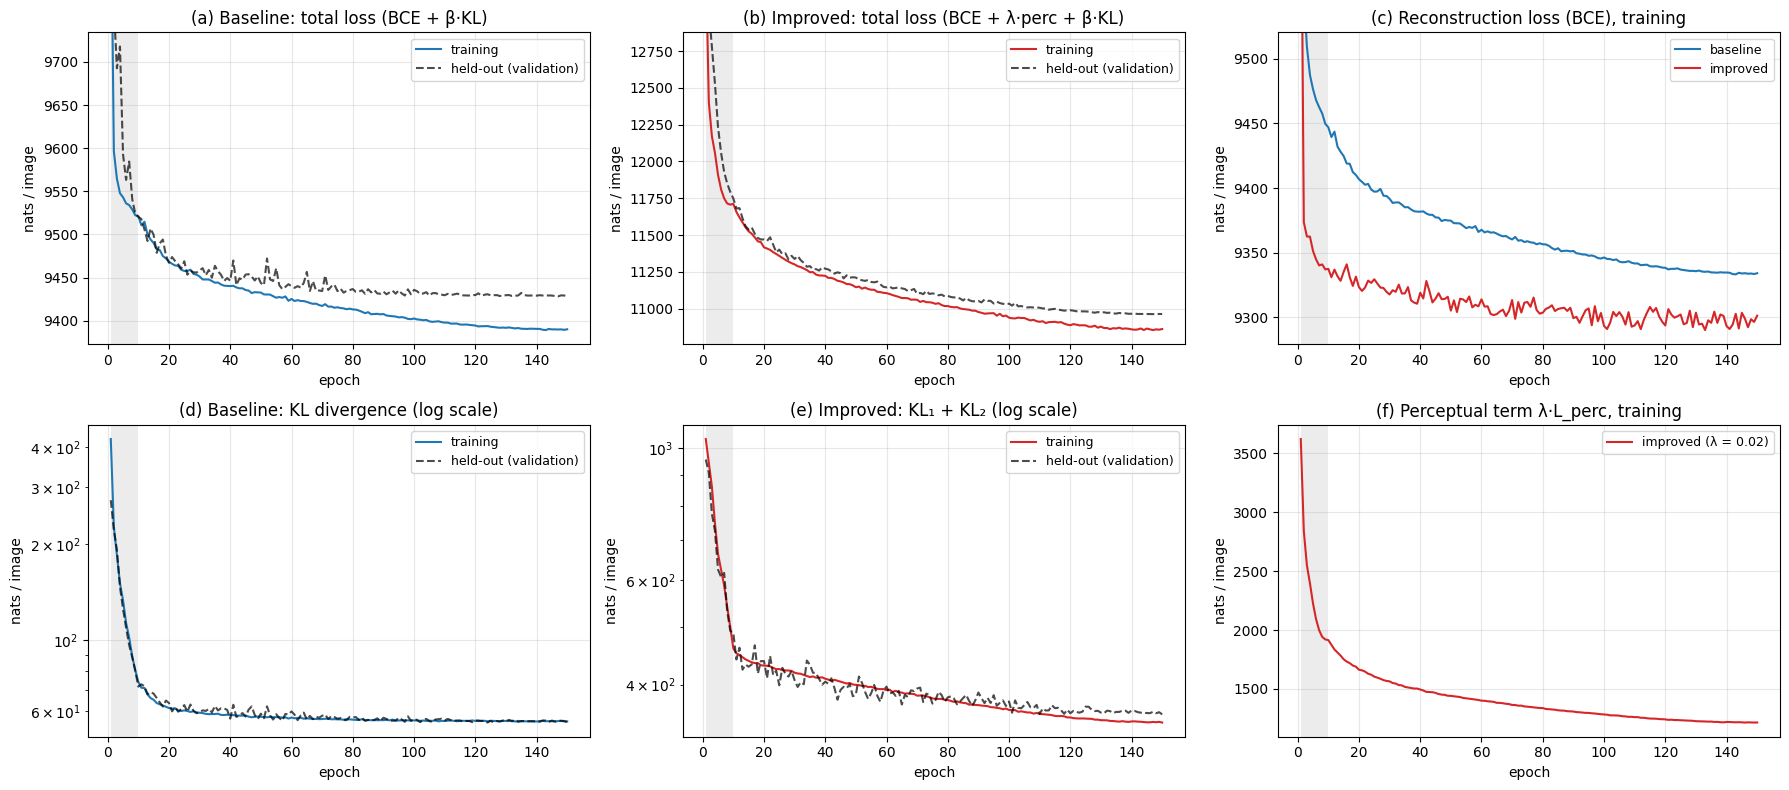

baseline : 150 epochs | final total loss train 9390.1 / held-out 9428.4 | KL train 55.9 / held-out 55.6
improved : 150 epochs | final total loss train 10860.9 / held-out 10962.8 | KL train 345.2 / held-out 356.3


In [10]:
def set_ylim_skip(a, curves, skip=2, pad=0.05):
    # Set the y-range from all curves while ignoring their first `skip` epochs, whose large values
    # would otherwise squash the converged part of the curves.
    lo = min(min(c) for c in curves)
    hi = max(max(c[skip:]) for c in curves)
    a.set_ylim(lo - pad * (hi - lo), hi + pad * (hi - lo))


def plot_train_vs_heldout(a, h, train_key, val_key, color, title, log=False):
    # Draw one model's training curve (solid) and held-out validation curve (dashed) on axis a.
    ep = np.arange(1, len(h[train_key]) + 1)
    a.plot(ep, h[train_key], color=color, label="training")
    a.plot(ep, h[val_key], "--", color="k", alpha=0.7, label="held-out (validation)")
    if log:
        a.set_yscale("log")
    else:
        set_ylim_skip(a, [h[train_key], h[val_key]])
    a.set_title(title)


def plot_training_losses(hb, hi, lam_perc, fname="loss_curves.png"):
    # 2x3 figure. Top: total loss of the baseline (a) and the improved model (b), training vs held-out,
    # and reconstruction BCE of both models (c). Bottom: KL divergence of the baseline (d) and the
    # improved model (e), training vs held-out, and the improved model's weighted perceptual term (f).
    # Saves the figure to outputs/<fname>.
    cb, ci = "tab:blue", "tab:red"
    fig, ax = plt.subplots(2, 3, figsize=(18, 8))
    plot_train_vs_heldout(ax[0, 0], hb, "train_obj", "val_obj", cb, "(a) Baseline: total loss (BCE + β·KL)")
    plot_train_vs_heldout(ax[0, 1], hi, "train_obj", "val_obj", ci,
                          "(b) Improved: total loss (BCE + λ·perc + β·KL)")
    for h, c, name in [(hb, cb, "baseline"), (hi, ci, "improved")]:
        ax[0, 2].plot(np.arange(1, len(h["train_bce"]) + 1), h["train_bce"], color=c, label=name)
    set_ylim_skip(ax[0, 2], [hb["train_bce"], hi["train_bce"]])
    ax[0, 2].set_title("(c) Reconstruction loss (BCE), training")

    plot_train_vs_heldout(ax[1, 0], hb, "train_kl", "val_kl", cb, "(d) Baseline: KL divergence (log scale)", log=True)
    plot_train_vs_heldout(ax[1, 1], hi, "train_kl", "val_kl", ci, "(e) Improved: KL₁ + KL₂ (log scale)", log=True)
    ax[1, 2].plot(np.arange(1, len(hi["train_perc"]) + 1), lam_perc * np.array(hi["train_perc"]), color=ci,
                  label=f"improved (λ = {lam_perc})")
    ax[1, 2].set_title("(f) Perceptual term λ·L_perc, training")

    for a in ax.flat:
        a.axvspan(1, CFG_BASE["kl_warmup"], color="grey", alpha=0.15, lw=0)
        a.set_xlabel("epoch"); a.set_ylabel("nats / image"); a.grid(alpha=.3); a.legend(fontsize=9)
    plt.tight_layout()
    plt.savefig(os.path.join(OUT_DIR, fname), bbox_inches="tight", dpi=150)
    plt.show()


plot_training_losses(hist_base, hist_impr, CFG_IMPR["lam_perc"])

for name, h in [("baseline", hist_base), ("improved", hist_impr)]:
    print(f"{name:9s}: {len(h['train_obj'])} epochs | final total loss train {h['train_obj'][-1]:.1f} / "
          f"held-out {h['val_obj'][-1]:.1f} | KL train {h['train_kl'][-1]:.1f} / held-out {h['val_kl'][-1]:.1f}")

## 7. Reconstructions, generated images, rib close-ups, latent interpolation

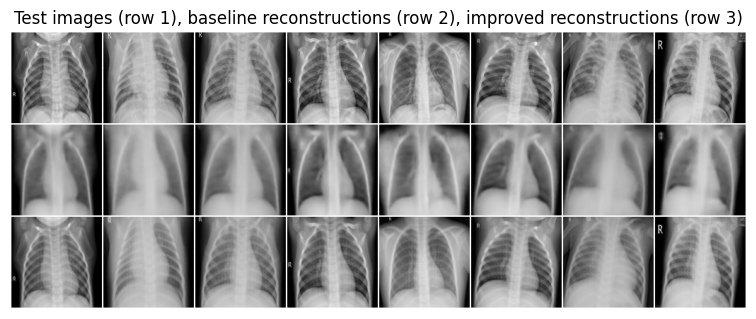

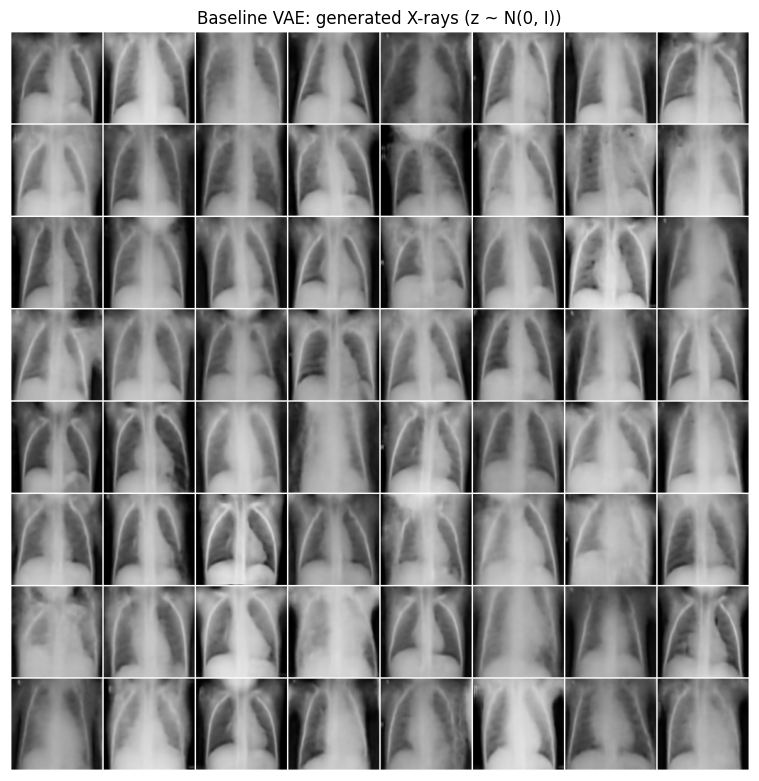

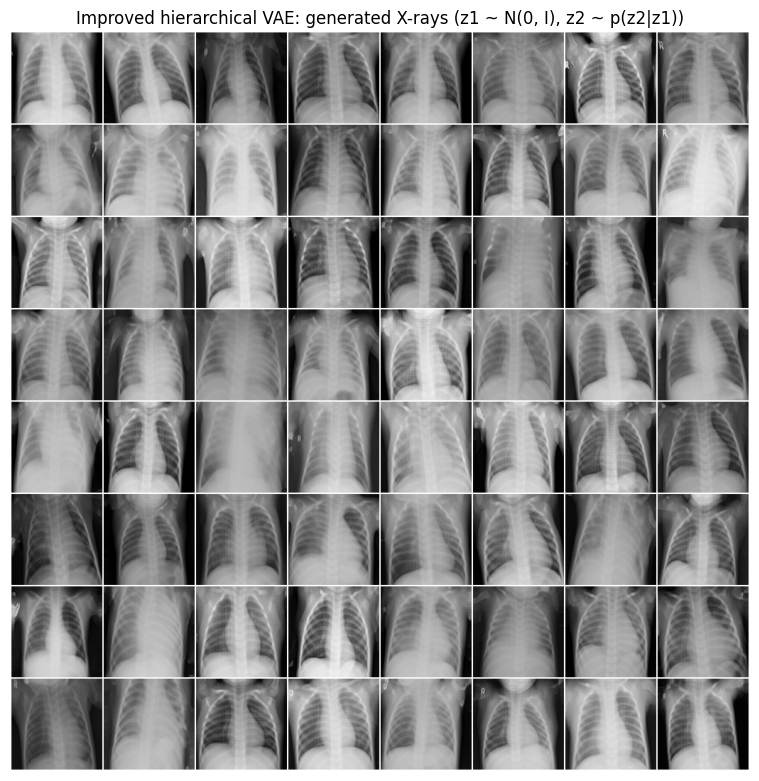

In [11]:
base_model.eval(); impr_model.eval()
set_seed(0)
xb = test_x[torch.randperm(len(test_x), device=device)[:8]]
show_grid(torch.cat([xb, base_model.reconstruct(xb), impr_model.reconstruct(xb)]),
          "Test images (row 1), baseline reconstructions (row 2), improved reconstructions (row 3)",
          nrow=8, fname="reconstructions.png")

set_seed(0)
samples_base = base_model.sample(64)
set_seed(0)
samples_impr = impr_model.sample(64)
show_grid(samples_base, "Baseline VAE: generated X-rays (z ~ N(0, I))", fname="generated_baseline.png")
show_grid(samples_impr, "Improved hierarchical VAE: generated X-rays (z1 ~ N(0, I), z2 ~ p(z2|z1))",
          fname="generated_improved.png")
vutils.save_image(samples_impr, os.path.join(OUT_DIR, "generated_improved_raw.png"), nrow=8)
vutils.save_image(samples_base, os.path.join(OUT_DIR, "generated_baseline_raw.png"), nrow=8)

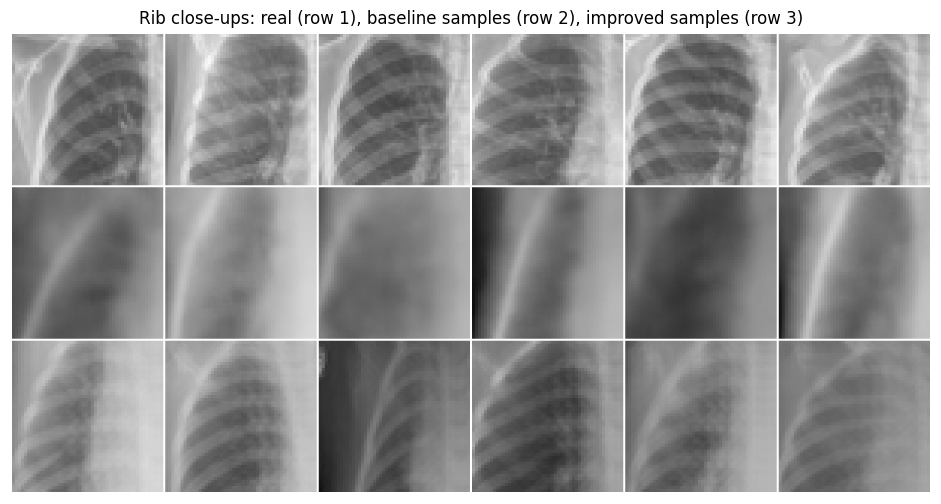

In [12]:
def rib_crops(imgs, box=(20, 70, 14, 64), up=3):
    # Crop a region over the right lung / ribs (rows y0:y1, cols x0:x1) and upsample it with
    # nearest-neighbour so edge detail can be compared at the pixel level.
    y0, y1, x0, x1 = box
    return F.interpolate(imgs[:, :, y0:y1, x0:x1], scale_factor=up, mode="nearest")


n = 6
show_grid(torch.cat([rib_crops(test_x[:n]), rib_crops(samples_base[:n]), rib_crops(samples_impr[:n])]),
          "Rib close-ups: real (row 1), baseline samples (row 2), improved samples (row 3)",
          nrow=n, fname="rib_closeups.png", scale=2.0)

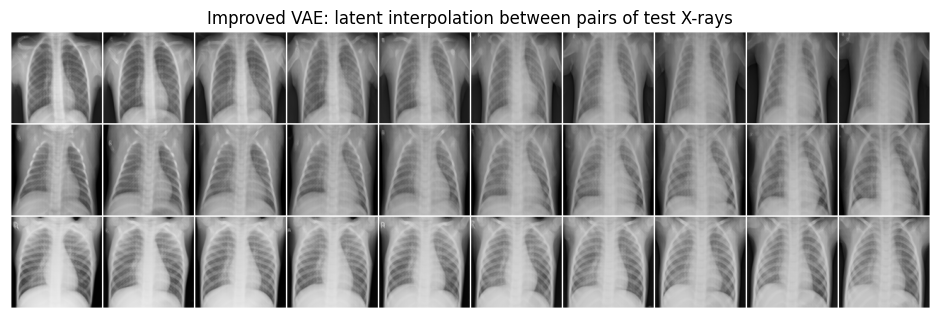

In [13]:
@torch.no_grad()
def interpolate_latent(model, x_a, x_b, steps=10):
    # Interpolate linearly between the global posterior means of two images and decode each point.
    # For the hierarchical model, z2 is drawn from p(z2|z1) with a fixed seed, so the path is smooth.
    mu_a, _ = model.encode_top(x_a[None]); mu_b, _ = model.encode_top(x_b[None])
    t = torch.linspace(0, 1, steps, device=device)[:, None]
    set_seed(0)
    return model.sample(steps, z=(1 - t) * mu_a + t * mu_b)


pairs = [(0, 300), (50, 500), (120, 600)]
show_grid(torch.cat([interpolate_latent(impr_model, test_x[i], test_x[j]) for i, j in pairs]),
          "Improved VAE: latent interpolation between pairs of test X-rays", nrow=10, fname="interpolation.png")

## 8. Inception Score and FID (pytorch-ignite)

This follows the ignite blog post: `FID` and `InceptionScore` metrics attach to an `Engine`, whose
`evaluation_step` returns `(fake, real)` batches. IS uses only the fake images
(`output_transform=lambda x: x[0]`). Inception-v3 expects $3\times299\times299$ input, so images are
bilinearly resized to 299×299 and the grayscale channel is repeated 3 times. We resize with
`F.interpolate` on the GPU (the blog uses PIL). Values stay in [0, 1], as in the blog.

`FID()` and `InceptionScore()` are used with their default arguments, as in the blog. In ignite, the
default FID is computed on the 1000-d *softmax output* of Inception-v3, not on the 2048-d pool features
used by other FID implementations. So the values are small, and they should only be compared with each
other, not with published FID numbers.

Generated images are compared with real **training** images (4,709 vs. 4,709). As a "real data"
reference, held-out **val + test** X-rays are scored the same way. That set has only 1,147 images, and
FID is biased upward for small sets, so the true real-vs-real floor is even lower.

In [14]:
from ignite.engine import Engine
from ignite.metrics import FID, InceptionScore


def to_inception(x: torch.Tensor) -> torch.Tensor:
    # Prepare (B,1,H,W) images in [0,1] for Inception-v3: bilinear resize to 299x299, 3 channels.
    x = F.interpolate(x, size=(299, 299), mode="bilinear", align_corners=False).clamp(0, 1)
    return x.repeat(1, 3, 1, 1)


def compute_is_fid(fake_fn, real_x: torch.Tensor, n: int, batch_size: int = 100) -> dict:
    # Run an ignite Engine over n real images. For each real batch, fake_fn(batch_size) returns the
    # images to score. Returns {'is': Inception Score of the fake images, 'fid': FID(fake, real)}.
    fid_metric = FID(device=device)
    is_metric = InceptionScore(device=device, output_transform=lambda x: x[0])

    def evaluation_step(engine, batch):
        with torch.no_grad():
            fake = fake_fn(len(batch))
            return to_inception(fake), to_inception(batch)

    evaluator = Engine(evaluation_step)
    fid_metric.attach(evaluator, "fid")
    is_metric.attach(evaluator, "is")
    idx = torch.randperm(len(real_x), device=real_x.device)[:n]
    batches = [real_x[idx[i:i + batch_size]] for i in range(0, len(idx), batch_size)]
    evaluator.run(batches, max_epochs=1)
    return {k: float(v) for k, v in evaluator.state.metrics.items()}


held_out = torch.cat([val_x, test_x])
n = min(N_EVAL, len(train_x))
t0 = time.time()
results = {}
set_seed(1); results["Baseline VAE"] = compute_is_fid(lambda m: base_model.sample(m), train_x, n)
set_seed(1); results["Improved VAE"] = compute_is_fid(lambda m: impr_model.sample(m), train_x, n)
set_seed(1)
_ptr = [0]
def held_out_fn(m):
    # Return the next m held-out real images (cycling through val + test).
    i = torch.arange(_ptr[0], _ptr[0] + m, device=device) % len(held_out); _ptr[0] += m
    return held_out[i]
results["Real held-out X-rays"] = compute_is_fid(held_out_fn, train_x, len(held_out))
print(f"evaluation took {time.time() - t0:.0f}s\n")

print(f"{'images scored':<24}{'IS ↑':>8}{'FID ↓':>10}")
for k, v in results.items():
    print(f"{k:<24}{v['is']:>8.3f}{v['fid']:>10.4f}")
with open(os.path.join(OUT_DIR, "metrics.json"), "w") as f:
    json.dump(results, f, indent=2)

evaluation took 30s

images scored               IS ↑     FID ↓
Baseline VAE               1.894    0.2267
Improved VAE               1.923    0.0168
Real held-out X-rays       2.179    0.0042


## 9. Summary for the report

Everything the report needs is saved in `outputs/`:

| Report item | File |
|---|---|
| Hyperparameters | `hparams.json` (also the `CFG_BASE` / `CFG_IMPR` cell) |
| Training loss curves | `loss_curves.png`, raw numbers in `history_*.json` |
| IS / FID | `metrics.json` (table printed above) |
| Generated examples | `generated_improved.png`, `generated_baseline.png`, `rib_closeups.png`, `reconstructions.png`, `interpolation.png` |
| Trained weights | `baseline.pt`, `improved.pt` |

**Results of our run** (the table printed in Part 8; re-running gives nearly the same values):

| Images scored | IS ↑ | FID ↓ (ignite) |
|---|---|---|
| Baseline VAE | 1.893 | 0.2268 |
| **Improved VAE** (hierarchical + perceptual loss) | **1.923** | **0.0168** |
| Real held-out X-rays (reference) | 2.178 | 0.0042 |

**Observations for the report**
* **Blur / rib edges.** Baseline samples have the right global anatomy, but the ribs are washed out
  (`rib_closeups.png`, row 2). The single 128-d latent can't encode each patient's rib pattern, and
  the per-pixel BCE loss rewards the blurry average. The hierarchical VAE stores local detail in the
  spatial latent $z_2$, and the perceptual loss makes that detail worth encoding. Its samples show
  distinct rib edges and lung texture (row 3), and FID falls by about **13×** (0.227 → 0.017). This
  closes most of the gap to the real-vs-real reference (0.004).
* **Over-fitting.** For the baseline (no augmentation or regularization), the val − train −ELBO gap rises
  steadily: from about −20 to **+15 nats** by epoch 150, crossing zero around epoch 80. The training
  loss keeps falling while the validation loss stalls. With augmentation, weight decay and checkpoint
  selection on validation, the improved model's gap stays **negative for all 150 epochs (−5.8 at the
  selected epoch 148)**. Its validation loss was still improving at the end, so early stopping
  (patience 30) never triggered, and the best checkpoint is from near the last epoch.
* **IS is a weak metric here.** Inception-v3 is trained on ImageNet, and every chest X-ray looks like the
  same few ImageNet classes to it. So even real X-rays only reach IS ≈ 2.2, and IS barely separates the
  models. FID is much more informative for this dataset.
* The perceptual weight $\lambda_{perc}$ was tuned in 60-epoch pilot runs: 0.005 helped less, and 0.05
  added artifacts and gave a worse FID. Without the perceptual loss, the hierarchical VAE hardly used
  $z_2$ (KL₂ ≈ 17 nats) and was no sharper than the baseline.